# Task 6: Explain a Different Model Using Kernel SHAP

In Task 2, we used Random Forest with Tree SHAP. Here, we use a different model: Support Vector Machine (SVM), explained with Kernel SHAP.

## 1. Install and import libraries

In [1]:
!pip install -q shap imbalanced-learn

In [2]:
import pandas as pd
import shap
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

## 2. Upload the dataset

In [3]:
uploaded = files.upload()
file_name = next(iter(uploaded))
data = pd.read_csv(file_name)
print(data.shape)
data.head()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. Preprocess the data

In [4]:
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
encoded = pd.get_dummies(data[categorical_cols], prefix=categorical_cols)
data = pd.concat([encoded, data], axis=1)
data.drop(categorical_cols, axis=1, inplace=True)
data['bmi'] = data['bmi'].fillna(0)
data.drop(['id'], axis=1, inplace=True)
X = data.drop('stroke', axis=1)
y = data['stroke']

## 4. Split the data

We use the same split setting as the earlier tasks.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2021)
print('Training:', X_train.shape)
print('Testing:', X_test.shape)

Training: (4088, 21)
Testing: (1022, 21)


## 5. Scale the features

SVM works better when features are on a similar scale. The scaler is fitted only on training data.

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Balance the training data

In [7]:
oversampler = RandomOverSampler(sampling_strategy='minority', random_state=2021)
X_train_balanced, y_train_balanced = oversampler.fit_resample(X_train_scaled, y_train)
print(y_train_balanced.value_counts())

stroke
0    3889
1    3889
Name: count, dtype: int64


## 7. Train the SVM model

We use `probability=True` so the model can return probabilities for Kernel SHAP.

In [8]:
model = SVC(kernel='rbf', probability=True, random_state=42)
model.fit(X_train_balanced, y_train_balanced)
print('SVM model training completed.')

SVM model training completed.


## 8. Check the SVM on the test set

The SVM is a different model from the Random Forest in Task 2. It uses the same split. The score explained later is the probability of stroke = 1.

In [9]:
y_pred = model.predict(X_test_scaled)
y_score = model.predict_proba(X_test_scaled)[:, 1]

print('Accuracy:', accuracy_score(y_test, y_pred))
print('Balanced accuracy:', balanced_accuracy_score(y_test, y_pred))
print('Precision for stroke = 1:', precision_score(y_test, y_pred, pos_label=1))
print('Recall for stroke = 1:', recall_score(y_test, y_pred, pos_label=1))
print('F1 for stroke = 1:', f1_score(y_test, y_pred, pos_label=1))
print('ROC AUC:', roc_auc_score(y_test, y_score))
print('Average precision:', average_precision_score(y_test, y_score))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7906066536203522
Balanced accuracy: 0.6148353909465021
Precision for stroke = 1: 0.10194174757281553
Recall for stroke = 1: 0.42
F1 for stroke = 1: 0.1640625
ROC AUC: 0.7037448559670781
Average precision: 0.13779697367260618
Confusion matrix:
[[787 185]
 [ 29  21]]


## 9. Create the Kernel SHAP explainer

A small sample of training data is used as the background to reduce calculation time.

In [10]:
background = shap.sample(X_train_scaled, 20, random_state=42)
explainer = shap.KernelExplainer(lambda values: model.predict_proba(values)[:, 1], background)
print('Kernel SHAP explainer created.')

Kernel SHAP explainer created.


## 10. Calculate SHAP values

We explain only five test examples because Kernel SHAP can take time.

In [11]:
X_explain = X_test_scaled[:5]
shap_values = explainer.shap_values(X_explain, nsamples=100)
print('SHAP values calculated.')

  0%|          | 0/5 [00:00<?, ?it/s]

SHAP values calculated.


## 11. Show a local explanation

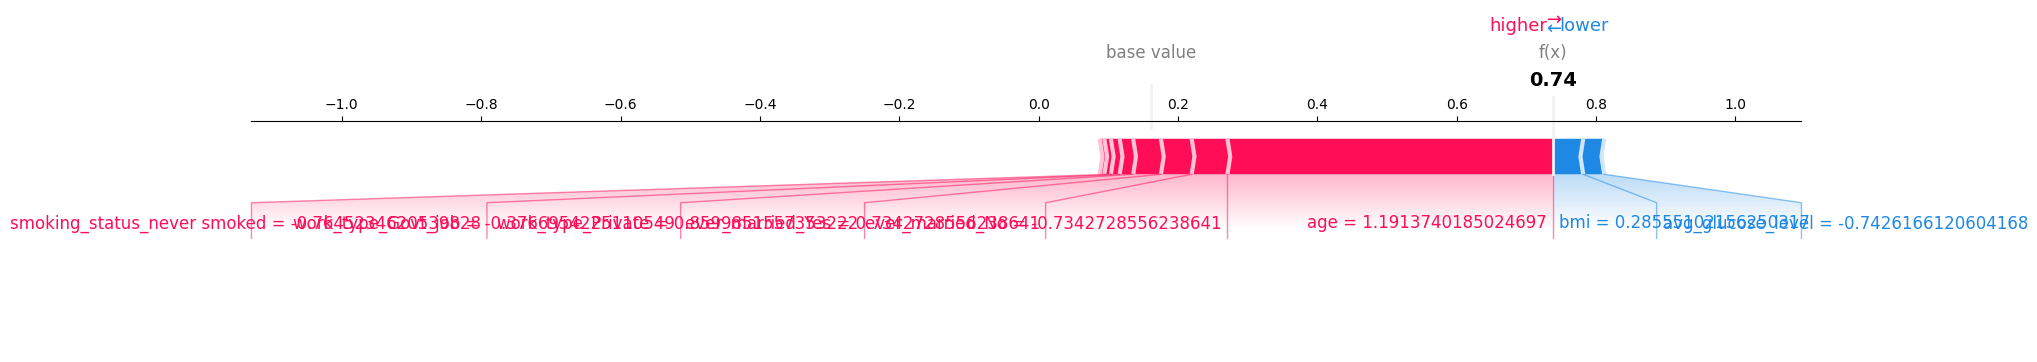

In [12]:
row = pd.Series(X_explain[0], index=X.columns)
shap.force_plot(explainer.expected_value, shap_values[0], row, matplotlib=True)
plt.show()

## 12. Show a global explanation

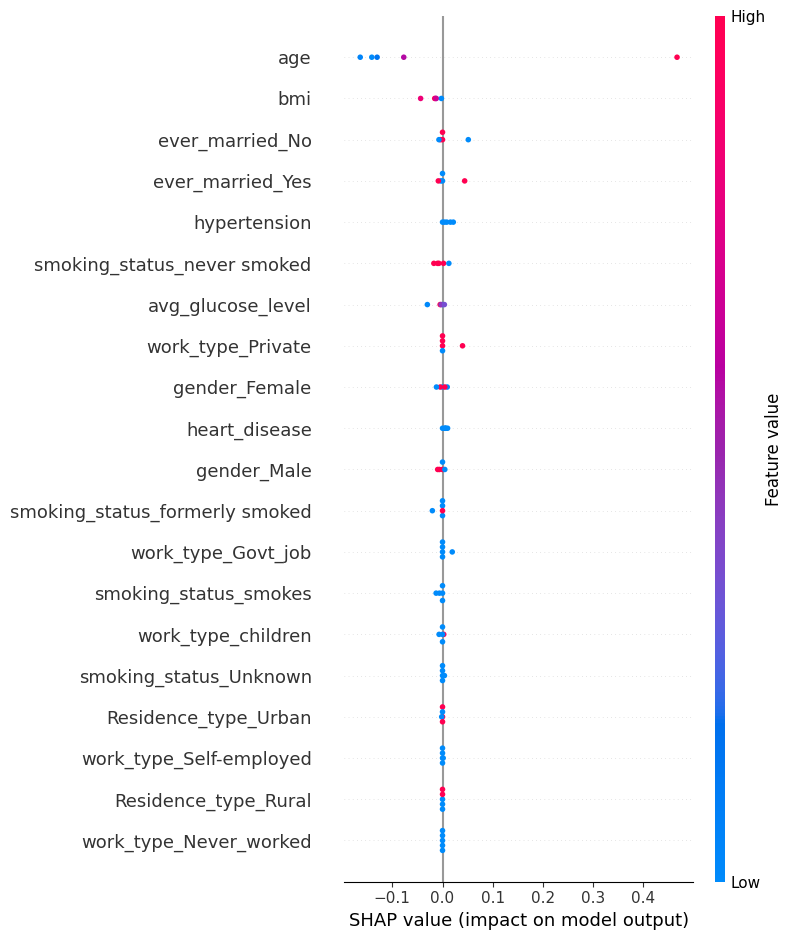

In [13]:
shap.summary_plot(shap_values, X_explain, feature_names=X.columns)

## 13. Compare the two models

Task 2 uses a Random Forest and TreeExplainer. This task uses an SVM and Kernel SHAP. Both explain the probability of stroke = 1. The Kernel SHAP plot uses only 20 background rows and 5 test rows, so it is a small sample.

In [14]:
print('Task 2 model: Random Forest with TreeExplainer')
print('Task 6 model: SVM with Kernel SHAP')
print('Same split: test_size = 0.20, random_state = 2021')
print('Explained output: probability of stroke = 1')
print('Kernel SHAP background rows: 20')
print('Kernel SHAP test rows: 5')

Task 2 model: Random Forest with TreeExplainer
Task 6 model: SVM with Kernel SHAP
Same split: test_size = 0.20, random_state = 2021
Explained output: probability of stroke = 1
Kernel SHAP background rows: 20
Kernel SHAP test rows: 5


## Task 6 completed

We trained an SVM model, which is different from the Random Forest model in Task 2, and used Kernel SHAP to explain its predictions. The small background and explanation samples help reduce computation time.